In [9]:
using JUDI, SlimPlotting, JLD2, HDF5, LinearAlgebra, SegyIO, Images, ImageFiltering
data_path = JUDI.JUDI_DATA

"/home/kerim.khemraev/.julia/dev/JUDI/src/../data"

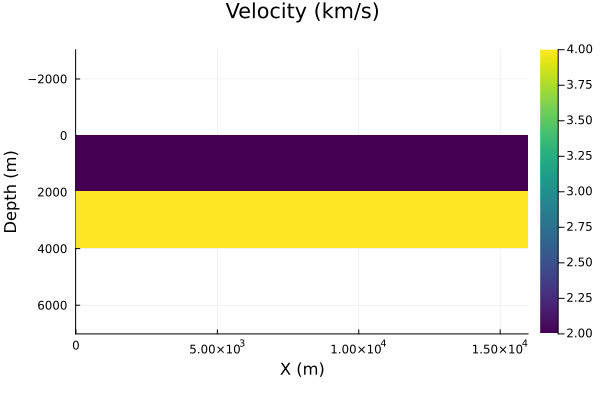

In [10]:
using SlimPlotting
# Set up model structure
n = (800, 200)   # (x,y,z) or (x,z)
d = (20., 20.)
o = (0., 0.)

# Velocity [km/s]
v = ones(Float32,n) .+ 1f0
v[:, Int(round(end/2)):end] .= 4f0

# Slowness squared [s^2/km^2]
m = (1f0 ./ v).^2


nx, nz = size(v)   # (120, 100)
x_coords = o[1] .+ d[1] .* (0:nx-1)   # 0, 10, 20, ..., 1190 м
z_coords = o[2] .+ d[2] .* (0:nz-1)   # 0, 10, 20, ..., 990 м (глубина)

using Plots

heatmap(x_coords, z_coords, v',
        yflip = true,               # глубина увеличивается вниз
        aspect_ratio = :equal,      # одинаковый масштаб по осям
        c = :viridis,               # цветовая палитра
        title = "Velocity (km/s)",
        xlabel = "X (m)",
        ylabel = "Depth (m)")

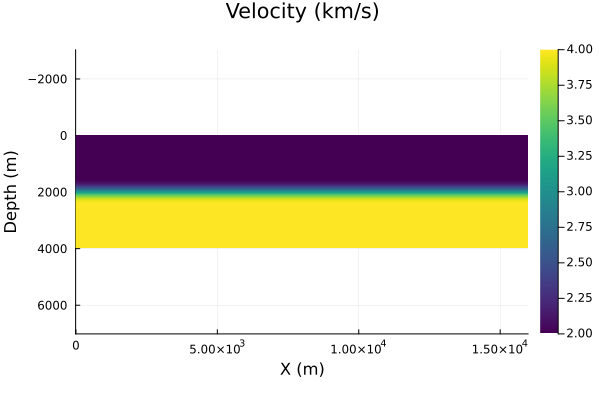

In [11]:
v0 = imfilter(Float32, v, Kernel.gaussian((10,10)))
m0 = (1f0 ./ v0).^2
dm = vec(m - m0);# Lets get some simple default parameter

heatmap(x_coords, z_coords, v0',
        yflip = true,               # глубина увеличивается вниз
        aspect_ratio = :equal,      # одинаковый масштаб по осям
        c = :viridis,               # цветовая палитра
        title = "Velocity (km/s)",
        xlabel = "X (m)",
        ylabel = "Depth (m)")


In [12]:
# Setup model structure
nsrc = 1	# number of sources
model = Model(n, d, o, m; nb=100)
model0 = Model(n, d, o, m0; nb=100)

# Set up receiver geometry
nxrec = 201
xrec = range(2000f0, stop=12000f0, length=nxrec)
yrec = 0f0
zrec = range(10f0, stop=10f0, length=nxrec)

# receiver sampling and recording time
time = 6000f0   # receiver recording time [ms]
dt = 2f0    # receiver sampling interval [ms]

# Set up receiver structure
rec_geometry = Geometry(xrec, yrec, zrec; dt=dt, t=time, nsrc=nsrc)

## Set up source geometry (cell array with source locations for each shot)
xsrc = convertToCell([2000f0])
ysrc = convertToCell([0f0])
zsrc = convertToCell([10f0])

# Set up source structure
src_geometry = Geometry(xsrc, ysrc, zsrc; dt=dt, t=time)

GeometryIC{Float32} wiht 1 sources


In [13]:
# setup wavelet
f0 = 0.008f0     # MHz
wavelet = ricker_wavelet(time, dt, f0)
q = judiVector(src_geometry, wavelet)

judiVector{Float32, Matrix{Float32}} with 1 sources


Operator `forward` ran in 0.12 s


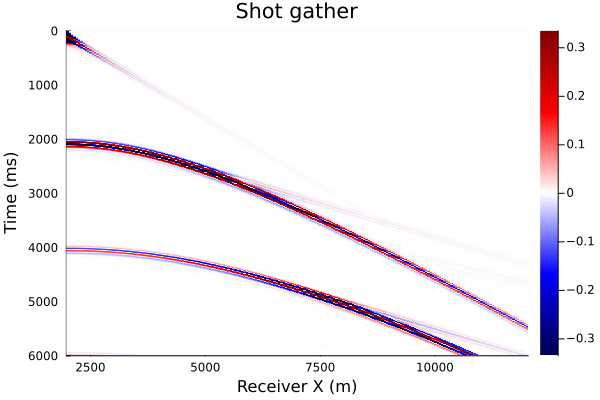

In [14]:
opt = Options(
    return_array=false,
    IC = "fwi",
    limit_m = true,
    buffer_size = (1000f0, 1000f0),
    optimal_checkpointing=false,
    subsampling_factor=2,
    # frequencies=[[0.005] for i in range(1,d_obs.nsrc)],
    # frequencies=[collect(range(0.002, frq, 10)) for i in range(1,d_obs.nsrc)],
    # frequencies = Array{Any}(undef, d_obs.nsrc),
    free_surface=true,  # free_surface is ON to model multiples as well
    space_order=16)     # increase space order for > 12 Hz source wavelet

F = judiModeling(model, src_geometry, rec_geometry; options=opt)
dobs = F(model)*q

dobs_data = dobs.data[1]


using Plots
using Statistics

# Временная ось
t_axis = collect(0:dt:time)      # 0:2:4000, длина 2001

# Ограничение амплитуд (99-й процентиль)
amp_max = quantile(vec(abs.(dobs_data)), 0.99)

heatmap(xrec, t_axis, dobs_data,
        yflip = true,
        aspect_ratio = :auto,
        c = :seismic,
        clim = (-amp_max, amp_max),
        xlabel = "Receiver X (m)",
        ylabel = "Time (ms)",
        title = "Shot gather")

Operator `forward` ran in 0.33 s
Operator `gradient` ran in 0.23 s


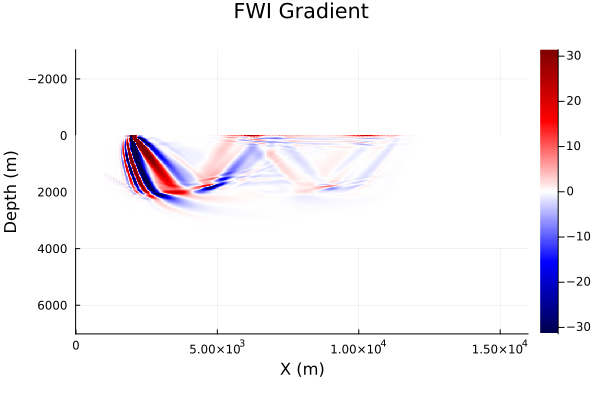

In [15]:
f, g = fwi_objective(model0, q, dobs; options=opt)

# Если g - это judiVector или PhysicalParameter, извлеките данные:
# g_vec = g.data   # если g имеет поле .data
g_vec = vec(g)      # если g - обычный массив

# Преобразуйте в матрицу размера модели
g_matrix = reshape(g_vec, n)   # n = (800, 200)

# Координаты (из ваших определений)
nx, nz = n
x_coords = o[1] .+ d[1] .* (0:nx-1)
z_coords = o[2] .+ d[2] .* (0:nz-1)

# Отображение
amp_max = quantile(vec(abs.(g_matrix)), 0.99)
heatmap(x_coords, z_coords, g_matrix',
        yflip = true, aspect_ratio = :equal,
        c = :seismic,
        clim = (-amp_max, amp_max),   # симметрично вокруг нуля
        title = "FWI Gradient",
        xlabel = "X (m)", ylabel = "Depth (m)")

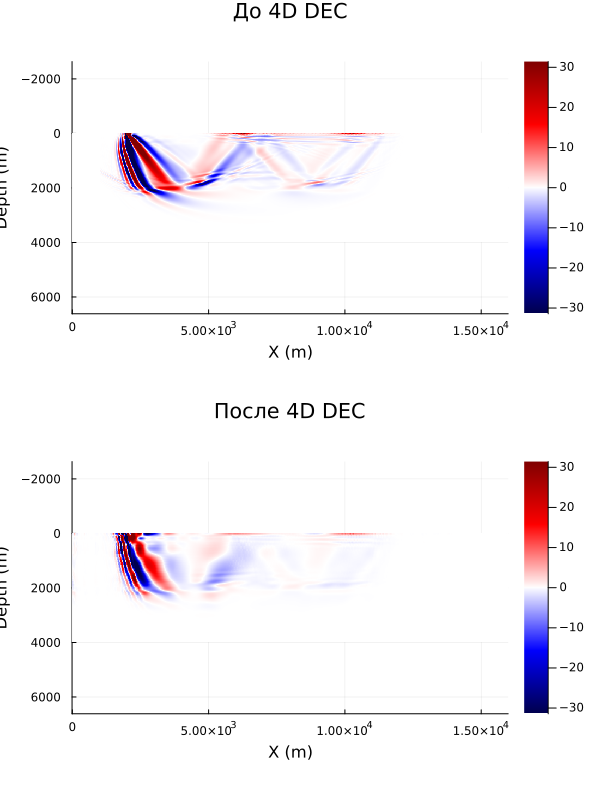

In [32]:
# ============================================================
# Реализация 4D DEC для подавления шума в градиенте FWI
# Ориентация данных: матрица (nz, nx) — строки: глубина Z, столбцы: X
# ============================================================

using Statistics
using LinearAlgebra

# ---------- Параметры алгоритма ----------
struct DECParams
    win_z::Int             # длина окна по Z (глубине) в отсчётах
    win_x::Int             # ширина окна по X (горизонтали) в отсчётах
    max_slope::Float32     # максимальный наклон dz/dx (в отсчётах Z на отсчёт X)
    slope_steps::Int       # количество наклонов (чем больше, тем дольше будет работать алгоритм)
    max_shift_z::Int       # максимальный статический сдвиг по Z (в отсчётах)
    amp_smooth_x::Int      # радиус сглаживания амплитуд по X
    static_smooth_x::Int   # радиус сглаживания статик по X
    x_inc::Int             # шаг перемещения окна по X
    z_inc::Int             # шаг перемещения окна по Z
    iterations::Int        # число проходов для разных наклонов
end

function DECParams(; win_z::Int, win_x::Int, max_slope::Float32, slope_steps::Int, max_shift_z::Int,
                   amp_smooth_x::Int, static_smooth_x::Int, x_inc::Int, z_inc::Int, iterations::Int)
    DECParams(win_z, win_x, max_slope, slope_steps, max_shift_z, amp_smooth_x, static_smooth_x, x_inc, z_inc, iterations)
end

# ---------- Вспомогательные функции ----------

# Треугольное сглаживание вектора (по X)
function triangular_smooth(v::Vector{Float32}, half_len::Int)
    n = length(v)
    out = similar(v)
    for i in 1:n
        lo = max(1, i - half_len)
        hi = min(n, i + half_len)
        weights = [half_len + 1 - abs(j - i) for j in lo:hi]
        out[i] = sum(v[lo:hi] .* weights) / sum(weights)
    end
    return out
end

# Поиск наилучшего целого сдвига по кросс-корреляции
function best_shift(trace, wavelet, max_shift)
    best_corr = -Inf
    best_s = 0
    for s in -max_shift:max_shift
        if s >= 0
            corr = dot(trace[1:end-s], wavelet[1+s:end])
        else
            corr = dot(trace[1-s:end], wavelet[1:end+s])
        end
        if corr > best_corr
            best_corr = corr
            best_s = s
        end
    end
    return best_s
end

# Оценка наклона (slope) путём перебора пробных значений
function estimate_slope(window::Matrix{Float32}, max_slope::Float32, slope_steps::Int)
    nz, nx = size(window)
    best_slope = 0.0f0
    best_energy = -Inf
    # Генерация наклонов с заданным числом шагов (slope_steps интервалов)
    slopes = collect(LinRange(-max_slope, max_slope, slope_steps + 1))
    for slope in slopes
        aligned = similar(window)
        for i in 1:nx
            shift = round(Int, slope * (i - (nx+1)/2))   # сдвиг относительно центра окна
            if shift >= 0
                aligned[1:nz-shift, i] = window[1+shift:nz, i]
                aligned[nz-shift+1:nz, i] .= 0
            else
                aligned[1-shift:nz, i] = window[1:nz+shift, i]
                aligned[1:-shift, i] .= 0
            end
        end
        stack = mean(aligned, dims=2)
        energy = sum(abs2, stack)
        if energy > best_energy
            best_energy = energy
            best_slope = slope
        end
    end
    return best_slope
end

# ---------- Обработка одного окна ----------
function process_window(window::Matrix{Float32}, params::DECParams)
    nz, nx = size(window)  # nz = win_z, nx = win_x
    
    # 1. Оценка наклона
    slope = estimate_slope(window, params.max_slope, params.slope_steps)
    
    # 2. Построение начального вейвлета (стек вдоль наклона)
    aligned = similar(window)
    for i in 1:nx
        shift = round(Int, slope * (i - (nx+1)/2))
        if shift >= 0
            aligned[1:nz-shift, i] = window[1+shift:nz, i]
            aligned[nz-shift+1:nz, i] .= 0
        else
            aligned[1-shift:nz, i] = window[1:nz+shift, i]
            aligned[1:-shift, i] .= 0
        end
    end
    wavelet = vec(mean(aligned, dims=2))
    
    # 3. Уточнение вейвлета и статик (2 итерации кросс-корреляции)
    statics = zeros(Int, nx)
    for iter in 1:2
        new_aligned = similar(window)
        for i in 1:nx
            base_shift = round(Int, slope * (i - (nx+1)/2))
            shifted_trace = circshift(window[:, i], -base_shift)
            stat = best_shift(shifted_trace, wavelet, params.max_shift_z)
            statics[i] = stat
            total_shift = base_shift + stat
            shifted_trace = circshift(window[:, i], -total_shift)
            new_aligned[:, i] = shifted_trace
        end
        wavelet = vec(mean(new_aligned, dims=2))
    end
    
    # 4. Оценка амплитуд для каждой трассы (столбца X)
    amps = zeros(Float32, nx)
    for i in 1:nx
        base_shift = round(Int, slope * (i - (nx+1)/2))
        total_shift = base_shift + statics[i]
        shifted_trace = circshift(window[:, i], -total_shift)
        amps[i] = dot(wavelet, shifted_trace) / dot(wavelet, wavelet)
    end
    
    # 5. Сглаживание амплитуд и статик (опционально)
    if params.amp_smooth_x > 0
        amps = triangular_smooth(amps, params.amp_smooth_x)
    end
    if params.static_smooth_x > 0
        statics_smoothed = triangular_smooth(Float32.(statics), params.static_smooth_x)
        statics = round.(Int, statics_smoothed)
    end
    
    # 6. Генерация модели окна
    model = zeros(Float32, nz, nx)
    for i in 1:nx
        base_shift = round(Int, slope * (i - (nx+1)/2))
        total_shift = base_shift + statics[i]
        shifted_wavelet = circshift(wavelet, total_shift)
        model[:, i] = amps[i] .* shifted_wavelet
    end
    
    return model
end

# ---------- Весовая функция (треугольная по X) ----------
function triangular_weights(n::Int)
    half = (n - 1) / 2
    return [half + 1 - abs(i - 1 - half) for i in 1:n]
end

# ---------- Основная функция: одна итерация 4D DEC ----------
function dec4d(data::Matrix{Float32}, params::DECParams)
    nz_total, nx_total = size(data)   # строки Z, столбцы X
    
    model_acc = zeros(Float32, nz_total, nx_total)
    weight_acc = zeros(Float32, nz_total, nx_total)
    
    win_z = params.win_z
    win_x = params.win_x
    x_inc = params.x_inc
    z_inc = params.z_inc

    # Двумерные веса для окна (треугольные по X и по Z)
    w_x = triangular_weights(win_x)
    w_z = triangular_weights(win_z)
    weight2D = w_z * w_x'   # размер (win_z, win_x)
    
    # Двойной цикл: по Z (внешний) и по X (внутренний)
    for z_start in 1:z_inc:(nz_total - win_z + 1)
        z_end = z_start + win_z - 1
        for x_start in 1:x_inc:(nx_total - win_x + 1)
            x_end = x_start + win_x - 1
            
            # Вырезаем двумерное окно
            window = data[z_start:z_end, x_start:x_end]   # размер (win_z, win_x)
            
            # Обработка окна
            model = process_window(window, params)   # размер (win_z, win_x)
            
            # Добавляем модель с двумерными весами
            model_acc[z_start:z_end, x_start:x_end] .+= weight2D .* model
            weight_acc[z_start:z_end, x_start:x_end] .+= weight2D
        end
    end
    
    # Итоговая модель сигнала
    denom = max.(weight_acc, eps(Float32))
    model_total = model_acc ./ denom
    
    return model_total
end

# ---------- Многократные итерации (для нескольких наклонов) ----------
function dec4d_multi_iterations(data::Matrix{Float32}, params::DECParams)
    residual = copy(data)
    total_model = zeros(Float32, size(data))
    for iter in 1:params.iterations
        model_iter = dec4d(residual, params)
        total_model .+= model_iter
        residual = data - total_model
    end
    return total_model, residual   # (модель сигнала, остаток = шум)
end

# ============================================================
# Пример использования (предполагается, что g_matrix уже загружена)
# ============================================================

# Преобразуем градиент в формат (nz, nx) и Float32
# Если g_matrix имеет размер (nx, nz), транспонируем:
# g_matrix = permutedims(g_matrix) # теперь (nz, nx)

g_matrix = Float32.(g_matrix)  # убедимся, что Float32

# Создаём параметры
params = DECParams(
    win_z = 200,            # 20 отсчётов по глубине (400 м)
    win_x = 100,            # 10 отсчётов по горизонтали (200 м)
    max_slope = 0.2f0,     # наклон 0.2 отсчёта Z на отсчёт X
    slope_steps = 5,   # например, 20 интервалов -> шаг 0.02 при max_slope=0.2
    max_shift_z = 0,       # статика до ±3 отсчётов
    amp_smooth_x = 3,      # сглаживание амплитуд по X (3 точки)
    static_smooth_x = 2,   # сглаживание статик по X (2 точки)
    x_inc = 20,             # шаг окна по X (2 точки)
    z_inc = 20,             # шаг окна по Z (2 точки)
    iterations = 3         # 3 прохода
)

# Запуск 4D DEC
model_signal, residual = dec4d_multi_iterations(g_matrix, params)

# Визуализация (с использованием Plots)
using Plots

# Координаты
nx_total, nz_total = size(g_matrix)   # (nz, nx) после транспонирования
x_coords = o[1] .+ d[1] .* (0:nx_total-1)
z_coords = o[2] .+ d[2] .* (0:nz_total-1)

# Функция для отображения
function plot_grad(data, title, amp_max)
    heatmap(x_coords, z_coords, data',
            yflip = true,
            aspect_ratio = :equal,
            c = :seismic,
            clim = (-amp_max, amp_max),
            title = title,
            xlabel = "X (m)",
            ylabel = "Depth (m)")
end

# Создаём график с двумя панелями, расположенными одна над другой
amp_max = quantile(vec(abs.(g_matrix)), 0.99)
p1 = plot_grad(g_matrix, "До 4D DEC", amp_max)
p2 = plot_grad(model_signal, "После 4D DEC", amp_max)

plot(p1, p2, layout = (2, 1), size = (600, 800))  # можно подобрать размер